# Delivery Delay Prediction

## 1. Data Preparation

Valuables
- `estimated_delivery_days`
- `customer_state`
- `seller_count`
- `item_count`
- `product_value`
- `freight_value`
- `distance_km`
- `order_purchase_timestamp`
- `total_product_weight_g` 
- `total_product_volume_cm3`
- `product_category` 
- `purchase_month`
-  `purchase_day_of_week`
-  `purchase_hour`
-  `is_weekend` <br>
  
  
Target
- `is_late_delivery` 

In [19]:
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from getpass import getpass
import numpy as np

In [8]:
# Connect to the local PostgreSQL database
db_url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=getpass("PostgreSQL password: "),
    host="localhost",
    port=5432,
    database="olist_ecommerce"
)

engine = create_engine(db_url)

PostgreSQL password:  ········


In [10]:
# Load historical orders for late delivery prediction
query = """
SELECT
    d.order_id,
    d.order_purchase_timestamp,
    d.is_late_delivery::integer AS is_late_delivery,
    (
        o.order_estimated_delivery_date::date
        - o.order_purchase_timestamp::date
    ) AS estimated_delivery_days,
    c.customer_state,
    s.item_count,
    s.seller_count,
    s.product_value,
    s.freight_value
FROM vw_order_delivery d
JOIN orders o
    ON d.order_id = o.order_id
JOIN vw_order_sales s
    ON d.order_id = s.order_id
JOIN customers c
    ON d.customer_id = c.customer_id
WHERE d.order_status = 'delivered'
    AND d.is_late_delivery IS NOT NULL
    AND d.order_purchase_timestamp >= '2017-01-01'
    AND d.order_purchase_timestamp < '2018-09-01'
ORDER BY d.order_purchase_timestamp, d.order_id
"""

model_data = pd.read_sql(query, engine)

In [11]:
# Check dataset size, target distribution and missing values
print("Rows:", len(model_data))
print("Unique orders:", model_data["order_id"].nunique())

print("\nTarget distribution:")
display(model_data["is_late_delivery"].value_counts())

print("\nLate delivery rate:")
print(f"{model_data['is_late_delivery'].mean() * 100:.2f}%")

print("\nMissing values:")
display(model_data.isna().sum().sort_values(ascending=False))

Rows: 96203
Unique orders: 96203

Target distribution:


is_late_delivery
0    89672
1     6531
Name: count, dtype: int64


Late delivery rate:
6.79%

Missing values:


order_id                    0
order_purchase_timestamp    0
is_late_delivery            0
estimated_delivery_days     0
customer_state              0
item_count                  0
seller_count                0
product_value               0
freight_value               0
dtype: int64

In [12]:
# Load geographical information for each order
query = """
SELECT
    oi.order_id,
    MIN(c.customer_zip_code_prefix) AS customer_zip_code_prefix,
    CASE
        WHEN COUNT(DISTINCT oi.seller_id) = 1
        THEN MIN(s.seller_state)
    END AS seller_state,
    CASE
        WHEN COUNT(DISTINCT oi.seller_id) = 1
        THEN MIN(s.seller_zip_code_prefix)
    END AS seller_zip_code_prefix
FROM order_items oi
JOIN orders o
    ON oi.order_id = o.order_id
JOIN customers c
    ON o.customer_id = c.customer_id
JOIN sellers s
    ON oi.seller_id = s.seller_id
GROUP BY oi.order_id
"""

geo_features = pd.read_sql(query, engine)

In [13]:
# Add geographical information to the modeling dataset
model_data = model_data.merge(
    geo_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Identify interstate deliveries for single-seller orders
model_data["is_interstate"] = (model_data["seller_state"] != model_data["customer_state"]).where(model_data["seller_state"].notna()).astype("Int64")

In [14]:
# Validate the geographical features
print("Rows:", len(model_data))
print("Unique orders:", model_data["order_id"].nunique())

print("\nMultiple-seller orders:")
print((model_data["seller_count"] > 1).sum())

print("\nMissing seller states:")
print(model_data["seller_state"].isna().sum())

print("\nInterstate delivery distribution:")
display(model_data["is_interstate"].value_counts(dropna=False))

display(model_data.head())

Rows: 96203
Unique orders: 96203

Multiple-seller orders:
1272

Missing seller states:
1272

Interstate delivery distribution:


is_interstate
1       60782
0       34149
<NA>     1272
Name: count, dtype: Int64

,order_id,order_purchase_timestamp,is_late_delivery,estimated_delivery_days,customer_state,item_count,seller_count,product_value,freight_value,customer_zip_code_prefix,seller_state,seller_zip_code_prefix,is_interstate
0,ec7a019261fce44180373d45b442d78f,2017-01-05 11:56:06,0,27,PR,1,1,10.9,8.72,80030,PR,81130,0
1,b95a0a8bd30aece4e94e81f0591249d8,2017-01-05 12:01:20,0,39,PR,1,1,10.9,8.72,80030,PR,81130,0
2,38bcb524e1c38c2c1b60600a80fc8999,2017-01-05 12:06:36,0,39,PR,1,1,2.9,8.72,80540,PR,81130,0
3,7a18a504c1a4b32d883e68de2e1a7db0,2017-01-05 12:09:08,0,39,PR,1,1,7.9,8.72,80540,PR,81130,0
4,6acecf438369055d9243e121045cca74,2017-01-05 12:11:23,0,39,PR,1,1,9.9,8.72,80540,PR,81130,0


In [15]:
# Load unique order-seller combinations
query = """
SELECT DISTINCT
    oi.order_id,
    oi.seller_id,
    s.seller_zip_code_prefix
FROM order_items oi
JOIN sellers s
    ON oi.seller_id = s.seller_id
"""

routes = pd.read_sql(query, engine)

In [16]:
# Keep orders included in the modeling dataset
routes = routes.merge(
    model_data[["order_id", "customer_zip_code_prefix"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

In [17]:
# Load median coordinates by ZIP code prefix
geo = pd.read_sql("SELECT * FROM vw_geolocation_prefix", engine)

geo = geo.rename(columns={"geolocation_zip_code_prefix": "zip_code_prefix"})

geo = geo[["zip_code_prefix", "latitude_mdn", "longitude_mdn"]]

# Add customer coordinates
routes = routes.merge(
    geo.rename(columns={
        "zip_code_prefix": "customer_zip_code_prefix",
        "latitude_mdn": "customer_lat",
        "longitude_mdn": "customer_lon"
    }),
    on="customer_zip_code_prefix",
    how="left",
    validate="many_to_one"
)

# Add seller coordinates
routes = routes.merge(
    geo.rename(columns={
        "zip_code_prefix": "seller_zip_code_prefix",
        "latitude_mdn": "seller_lat",
        "longitude_mdn": "seller_lon"
    }),
    on="seller_zip_code_prefix",
    how="left",
    validate="many_to_one"
)

In [20]:
# Convert coordinates to radians
lat1 = np.radians(routes["seller_lat"].astype(float))
lon1 = np.radians(routes["seller_lon"].astype(float))

lat2 = np.radians(routes["customer_lat"].astype(float))
lon2 = np.radians(routes["customer_lon"].astype(float))

# Calculate straight-line distance using the Haversine formula
a = (np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)

routes["route_distance_km"] = (2 * 6371 * np.arcsin(np.sqrt(np.clip(a, 0, 1))))

In [21]:
# Aggregate shipping distances at the order level
distance_features = (
    routes.groupby("order_id")
    .agg(
        distance_km=("route_distance_km", "max"),
        sellers_with_distance=("route_distance_km", "count")
    )
    .reset_index()
)

# Add distance features to the modeling dataset
model_data = model_data.merge(
    distance_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Require distances for all sellers in an order
model_data.loc[model_data["sellers_with_distance"] != model_data["seller_count"], "distance_km"] = np.nan

model_data = model_data.drop(columns="sellers_with_distance")

In [22]:
# Validate distance features
print("Rows:", len(model_data))
print("Unique orders:", model_data["order_id"].nunique())

print("\nMissing distances:")
print(model_data["distance_km"].isna().sum())

print("\nMissing distances by seller count:")
display(model_data.groupby(model_data["seller_count"] > 1)["distance_km"].apply(lambda x: x.isna().sum()))

print("\nDistance statistics:")
display(model_data["distance_km"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(2))

Rows: 96203
Unique orders: 96203

Missing distances:
480

Missing distances by seller count:


seller_count
False    470
True      10
Name: distance_km, dtype: int64


Distance statistics:


count    95723.00
mean       601.96
std        594.23
min          0.00
50%        435.53
75%        800.11
90%       1457.37
95%       2096.14
99%       2483.27
max       8677.86
Name: distance_km, dtype: float64

In [23]:
# Calculate product features at the order level
# If an order contains three products but the weight 
# of one is missing, do not return the sum of the weights of the other two as the total weight for the entire order. 
#It is better to return "NaN" than to underestimate the volume.


query = """
SELECT
    oi.order_id,
    COUNT(*) AS product_items,

    CASE
        WHEN COUNT(p.product_weight_g) = COUNT(*) 
        THEN SUM(p.product_weight_g)
    END AS total_product_weight_g,

    CASE
        WHEN COUNT(p.product_length_cm) = COUNT(*)
         AND COUNT(p.product_height_cm) = COUNT(*)
         AND COUNT(p.product_width_cm) = COUNT(*)
        THEN SUM(
            p.product_length_cm::numeric
            * p.product_height_cm
            * p.product_width_cm
        )
    END AS total_product_volume_cm3,

    CASE
        WHEN COUNT(DISTINCT COALESCE(p.product_category_name, 'unknown')) = 1
        THEN MIN(COALESCE(p.product_category_name, 'unknown'))
        ELSE 'multiple_categories'
    END AS product_category

FROM order_items oi
LEFT JOIN products p
    ON oi.product_id = p.product_id
GROUP BY oi.order_id
"""

product_features = pd.read_sql(query, engine)

In [24]:
# Add product features to the modeling dataset
model_data = model_data.merge(
    product_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the number of items
print("Item count mismatches:", (model_data["item_count"] != model_data["product_items"]).sum())

# Remove the duplicate item count column
model_data = model_data.drop(columns="product_items")

Item count mismatches: 0


In [25]:
# Validate product features
print("Rows:", len(model_data))
print("Unique orders:", model_data["order_id"].nunique())

print("\nMissing product features:")
display(
    model_data[
        [
            "total_product_weight_g",
            "total_product_volume_cm3",
            "product_category"
        ]
    ].isna().sum()
)

print("\nProduct feature statistics:")
display(model_data[["total_product_weight_g", "total_product_volume_cm3"]].describe().round(2))

print("\nTop product categories:")
display(model_data["product_category"].value_counts().head(10))

Rows: 96203
Unique orders: 96203

Missing product features:


total_product_weight_g      16
total_product_volume_cm3    16
product_category             0
dtype: int64


Product feature statistics:


,total_product_weight_g,total_product_volume_cm3
count,96187.00,96187.00
mean,2386.34,17323.27
std,4771.64,30153.46
min,0.00,168.00
25%,300.00,2964.00
50%,750.00,7240.00
75%,2050.00,19838.00
max,184400.00,1476000.00



Top product categories:


product_category
cama_mesa_banho           9066
beleza_saude              8539
esporte_lazer             7440
informatica_acessorios    6466
moveis_decoracao          6056
utilidades_domesticas     5618
relogios_presentes        5449
telefonia                 4059
automotivo                3765
brinquedos                3730
Name: count, dtype: int64

In [27]:
# Extract time-based features from the purchase timestamp
model_data["order_purchase_timestamp"] = pd.to_datetime(model_data["order_purchase_timestamp"])

model_data["purchase_month"] = (model_data["order_purchase_timestamp"].dt.month)

model_data["purchase_day_of_week"] = (model_data["order_purchase_timestamp"].dt.dayofweek)

model_data["purchase_hour"] = (model_data["order_purchase_timestamp"].dt.hour)

model_data["is_weekend"] = (model_data["purchase_day_of_week"] >= 5).astype(int)

,purchase_month,purchase_day_of_week,purchase_hour,is_weekend
count,96203.000000,96203.000000,96203.000000,96203.000000
mean,6.020020,2.756806,14.773146,0.230045
std,3.226148,1.967254,5.328050,0.420863
min,1.000000,0.000000,0.000000,0.000000
25%,3.000000,1.000000,11.000000,0.000000
50%,6.000000,3.000000,15.000000,0.000000
75%,8.000000,4.000000,19.000000,0.000000
max,12.000000,6.000000,23.000000,1.000000



Missing values:


purchase_month          0
purchase_day_of_week    0
purchase_hour           0
is_weekend              0
dtype: int64

In [28]:
# Check monthly target distribution before chronological splitting
model_data["purchase_period"] = (model_data["order_purchase_timestamp"].dt.to_period("M"))

monthly_target = (
    model_data.groupby("purchase_period")
    .agg(
        orders=("order_id", "size"),
        late_orders=("is_late_delivery", "sum"),
        late_rate_pct=("is_late_delivery", lambda x: x.mean() * 100)
    )
    .round(2)
)

display(monthly_target)

,orders,late_orders,late_rate_pct
purchase_period,,,
2017-01,750,22,2.93
2017-02,1653,49,2.96
2017-03,2546,116,4.56
2017-04,2303,151,6.56
2017-05,3545,106,2.99
2017-06,3135,95,3.03
2017-07,3872,108,2.79
2017-08,4193,122,2.91
2017-09,4150,182,4.39


## 2. Temporal Data Split

**Can the model generalize to subsequent orders, despite changing logistical conditions?**

Avoiding the use of a random `train_test_split`.

Proposed data split
- Training:	Jan 2017 – Feb 2018	Model training
- Validation:	Mar 2018 – May 2018	Model comparison, hyperparameter tuning, and risk threshold selection
- Test: 	Jun 2018 – Aug 2018	Final evaluation of the selected model

This split offers several advantages.

The `Training set` includes both periods of good on-time performance and significant spikes in delays—specifically in November 2017 and February 2018.

The `Validation set` covers the largest monthly surge in delays (March 2018), allowing for an assessment of the model's effectiveness under challenging conditions.

The `Test set` covers later months, during which the incidence of delays is significantly lower, making it possible to verify how well the model handles shifts in the frequency of delays.


In [29]:
# Define chronological split boundaries
train_end = pd.Timestamp("2018-03-01")
validation_end = pd.Timestamp("2018-06-01")

# Split orders by purchase date
train_data = model_data[model_data["order_purchase_timestamp"] < train_end].copy()

val_data = model_data[(model_data["order_purchase_timestamp"] >= train_end) & (model_data["order_purchase_timestamp"] < validation_end)].copy()

test_data = model_data[model_data["order_purchase_timestamp"] >= validation_end].copy()

# Summarize class distribution across datasets
split_summary = pd.DataFrame({
    "orders": [
        len(train_data),
        len(val_data),
        len(test_data)
    ],
    "late_orders": [
        train_data["is_late_delivery"].sum(),
        val_data["is_late_delivery"].sum(),
        test_data["is_late_delivery"].sum()
    ],
    "late_rate_pct": [
        train_data["is_late_delivery"].mean() * 100,
        val_data["is_late_delivery"].mean() * 100,
        test_data["is_late_delivery"].mean() * 100
    ]
}, index=["Training", "Validation", "Test"])

display(split_summary.round(2))

,orders,late_orders,late_rate_pct
Training,57050,3782,6.63
Validation,20550,2077,10.11
Test,18603,672,3.61


In [30]:
# Load actual delivery dates
delivery_dates = pd.read_sql(
    """
    SELECT order_id, order_delivered_customer_date
    FROM orders
    WHERE order_status = 'delivered'
    """,
    engine
)

delivery_dates["order_delivered_customer_date"] = pd.to_datetime(
    delivery_dates["order_delivered_customer_date"]
)

# Check when delivery outcomes became available
for name, dataset, cutoff in [
    ("Training", train_data, pd.Timestamp("2018-03-01")),
    ("Validation", val_data, pd.Timestamp("2018-06-01"))
]:

    check = dataset[["order_id"]].merge(
        delivery_dates,
        on="order_id",
        how="left",
        validate="one_to_one"
    )

    unavailable = (
        check["order_delivered_customer_date"].isna()
        | (check["order_delivered_customer_date"] >= cutoff)
    )

    print(
        f"{name}: {unavailable.sum()} outcomes unavailable "
        f"at cutoff ({unavailable.mean() * 100:.2f}%)"
    )

Training: 3673 outcomes unavailable at cutoff (6.44%)
Validation: 2433 outcomes unavailable at cutoff (11.84%)


In [31]:
# Compare late delivery rates by label availability at each cutoff
for name, dataset, cutoff in [
    ("Training", train_data, pd.Timestamp("2018-03-01")),
    ("Validation", val_data, pd.Timestamp("2018-06-01"))
]:

    check = dataset[
        ["order_id", "is_late_delivery"]
    ].merge(
        delivery_dates,
        on="order_id",
        how="left",
        validate="one_to_one"
    )

    check["label_available"] = (
        check["order_delivered_customer_date"].notna()
        & (check["order_delivered_customer_date"] < cutoff)
    )

    summary = (
        check.groupby("label_available")
        .agg(
            orders=("order_id", "size"),
            late_orders=("is_late_delivery", "sum"),
            late_rate_pct=(
                "is_late_delivery",
                lambda x: x.mean() * 100
            )
        )
        .round(2)
    )

    print(f"\n{name}")
    display(summary)


Training


,orders,late_orders,late_rate_pct
label_available,,,
False,3673,1075,29.27
True,53377,2707,5.07



Validation


,orders,late_orders,late_rate_pct
label_available,,,
False,2433,489,20.10
True,18117,1588,8.77


> Removing orders that were not delivered before the cutoff date could significantly distort the training data.

In [32]:
# Check label availability using delivery and estimated dates
for name, dataset, cutoff in [
    ("Training", train_data, pd.Timestamp("2018-03-01")),
    ("Validation", val_data, pd.Timestamp("2018-06-01"))
]:

    check = dataset[
        ["order_id", "order_purchase_timestamp", "estimated_delivery_days"]
    ].merge(
        delivery_dates,
        on="order_id",
        how="left",
        validate="one_to_one"
    )

    # Reconstruct the estimated delivery deadline
    estimated_date = (check["order_purchase_timestamp"].dt.normalize() + pd.to_timedelta(check["estimated_delivery_days"], unit="D"))

    # The outcome is known after delivery or after the deadline has passed
    label_known = ((check["order_delivered_customer_date"] < cutoff) | (estimated_date < cutoff))

    print(f"\n{name}")
    print(f"Known outcomes: {label_known.sum()}")
    print(f"Unknown outcomes: {(~label_known).sum()}")
    print(f"Unknown share: {(~label_known).mean() * 100:.2f}%")


Training
Known outcomes: 53511
Unknown outcomes: 3539
Unknown share: 6.20%

Validation
Known outcomes: 18293
Unknown outcomes: 2257
Unknown share: 10.98%


**Temporal Data Split Strategy**

A chronological split was used to simulate predicting delivery delays for future orders and to prevent data leakage.

- Training (Jan 2017 – Feb 2018): Only delivery outcomes known by March 1, 2018, were included.
- Validation (Mar – May 2018): Only outcomes known by July 1, 2018, were used for model selection and threshold optimization.
- Temporal Gap (June 2018): A one-month gap was introduced to allow additional delivery outcomes to become available before final testing.
- Test (Jul – Aug 2018): Reserved for the final evaluation on unseen, later orders.

Delivery outcomes were considered known if the order had already been delivered or its estimated delivery deadline had passed.

Rationale: Delivery labels become available with a delay. Using future outcomes during training would introduce data leakage, while excluding unresolved orders may introduce selection bias. This strategy prioritizes temporal validity, with the potential selection bias documented as a limitation.

In [33]:
# Look up actual delivery dates by order ID
delivery_lookup = delivery_dates.set_index("order_id")["order_delivered_customer_date"]

# Check which delivery outcomes were known at a given date
def known_outcomes(data, cutoff):
    delivered = data["order_id"].map(delivery_lookup)

    estimated = (data["order_purchase_timestamp"].dt.normalize() + pd.to_timedelta(data["estimated_delivery_days"], unit="D"))

    return (delivered < cutoff) | (estimated < cutoff)


# Keep only labels available at the training cutoff
train_known = known_outcomes(train_data, pd.Timestamp("2018-03-01"))

train_ready = train_data.loc[train_known].copy()


# Allow an additional month for validation outcomes
val_known = known_outcomes(val_data, pd.Timestamp("2018-07-01"))

val_ready = val_data.loc[val_known].copy()


# Reserve July and August for final testing
test_ready = test_data[test_data["order_purchase_timestamp"] >= "2018-07-01"].copy()

In [34]:
# Summarize the final modeling datasets
split_summary_final = pd.DataFrame({
    "orders": [
        len(train_ready),
        len(val_ready),
        len(test_ready)
    ],
    "late_orders": [
        train_ready["is_late_delivery"].sum(),
        val_ready["is_late_delivery"].sum(),
        test_ready["is_late_delivery"].sum()
    ],
    "late_rate_pct": [
        train_ready["is_late_delivery"].mean() * 100,
        val_ready["is_late_delivery"].mean() * 100,
        test_ready["is_late_delivery"].mean() * 100
    ]
}, index=["Training", "Validation", "Test"])

display(split_summary_final.round(2))

print("Validation outcomes unavailable on July 1:", (~val_known).sum())

,orders,late_orders,late_rate_pct
Training,53511,2841,5.31
Validation,20539,2073,10.09
Test,12507,601,4.81


Validation outcomes unavailable on July 1: 11


## 3. Data Preprocessing

In [35]:
# Inspect numerical features in the training dataset
numeric_features = [
    "estimated_delivery_days",
    "distance_km",
    "item_count",
    "seller_count",
    "product_value",
    "freight_value",
    "total_product_weight_g",
    "total_product_volume_cm3"
]

display(
    train_ready[numeric_features]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
    .round(2)
)

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
estimated_delivery_days,53511.0,25.46,7.72,8.00,11.00,21.00,25.00,30.00,38.00,49.00,156.00
distance_km,53232.0,611.05,592.91,0.00,6.01,215.76,445.84,808.83,2094.73,2489.20,8032.93
item_count,53511.0,1.14,0.53,1.00,1.00,1.00,1.00,1.00,2.00,3.00,21.00
seller_count,53511.0,1.01,0.12,1.00,1.00,1.00,1.00,1.00,1.00,2.00,5.00
product_value,53511.0,135.29,208.51,2.29,11.90,45.90,84.99,149.90,395.00,980.79,13440.00
freight_value,53511.0,21.81,18.94,0.00,7.78,14.00,16.46,23.43,50.42,94.94,1002.29
total_product_weight_g,53495.0,2462.86,4805.13,50.00,100.00,300.00,800.00,2150.00,10750.00,22600.00,184400.00
total_product_volume_cm3,53495.0,18253.53,31120.66,288.00,352.00,3080.00,8000.00,20808.00,66965.40,139647.50,1476000.00


In [36]:
# Check zero and negative values in selected numerical features
features_to_check = [
    "estimated_delivery_days",
    "distance_km",
    "product_value",
    "freight_value",
    "total_product_weight_g",
    "total_product_volume_cm3"
]

quality_check = pd.DataFrame({
    "missing": train_ready[features_to_check].isna().sum(),
    "zero": (train_ready[features_to_check] == 0).sum(),
    "negative": (train_ready[features_to_check] < 0).sum()
})

display(quality_check)

,missing,zero,negative
estimated_delivery_days,0,0,0
distance_km,279,12,0
product_value,0,0,0
freight_value,0,10,0
total_product_weight_g,16,0,0
total_product_volume_cm3,16,0,0


In [37]:
# Inspect unusually large shipping distances
suspicious_distances = (
    train_ready[
        train_ready["distance_km"] > 4000
    ][
        [
            "order_id",
            "customer_state",
            "seller_state",
            "seller_count",
            "distance_km",
            "is_late_delivery"
        ]
    ]
    .sort_values("distance_km", ascending=False)
)

print("Orders with distance > 4000 km:", len(suspicious_distances))

display(suspicious_distances.head(15).round(2))

Orders with distance > 4000 km: 3


,order_id,customer_state,seller_state,seller_count,distance_km,is_late_delivery
31187,acdbc7396e191931c263db11af241d62,PA,SP,1,8032.93,0
34437,4d5abe7999d76d1fb6237d3677706af0,PA,SP,1,8032.93,0
6333,897ec6416d50126a9061626f0fc2d658,BA,SP,1,4791.61,0


In [38]:
# Inspect coordinates of orders with suspicious distances
display(
    routes.loc[
        routes["order_id"].isin(suspicious_distances["order_id"]),
        [
            "order_id",
            "customer_zip_code_prefix",
            "seller_zip_code_prefix",
            "customer_lat",
            "customer_lon",
            "seller_lat",
            "seller_lon",
            "route_distance_km"
        ]
    ].round(2)
)

,order_id,customer_zip_code_prefix,seller_zip_code_prefix,customer_lat,customer_lon,seller_lat,seller_lon,route_distance_km
29537,4d5abe7999d76d1fb6237d3677706af0,68275,14110,41.15,-8.58,-21.26,-47.81,8032.93
52188,897ec6416d50126a9061626f0fc2d658,46560,05849,13.00,-23.58,-23.65,-46.76,4791.61
65647,acdbc7396e191931c263db11af241d62,68275,14110,41.15,-8.58,-21.26,-47.81,8032.93


> The coordinates incorrectly point to Portugal and Cape Verde—all the orders are from Brazil. These are erroneous records.

In [39]:
# Flag shipping routes with coordinates outside Brazil's approximate bounds
invalid_coordinates = (
    ~routes["customer_lat"].between(-34, 6)
    | ~routes["customer_lon"].between(-74, -34)
    | ~routes["seller_lat"].between(-34, 6)
    | ~routes["seller_lon"].between(-74, -34)
)

# Identify orders with calculated distances based on invalid coordinates
invalid_geo_orders = routes.loc[invalid_coordinates & routes["route_distance_km"].notna(), "order_id"].unique()

# Keep the orders but invalidate their distance feature
for data in [model_data, train_ready, val_ready, test_ready]:
    data.loc[
        data["order_id"].isin(invalid_geo_orders),
        "distance_km"
    ] = np.nan

print("Orders with invalid coordinates:", len(invalid_geo_orders))
print("Missing distances in training:", train_ready["distance_km"].isna().sum())
print("Missing distances in validation:", val_ready["distance_km"].isna().sum())
print("Missing distances in test:", test_ready["distance_km"].isna().sum())

Orders with invalid coordinates: 4
Missing distances in training: 282
Missing distances in validation: 102
Missing distances in test: 53


## 4. Model Development

### 4.1 Feature Selection

In [41]:
# Define numerical and categorical features
numeric_features = [
    "estimated_delivery_days",
    "distance_km",
    "item_count",
    "seller_count",
    "product_value",
    "freight_value",
    "total_product_weight_g",
    "total_product_volume_cm3",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "is_weekend",
    "is_interstate"
]

categorical_features = [
    "customer_state",
    "seller_state",
    "product_category"
]

feature_columns = numeric_features + categorical_features
target = "is_late_delivery"

In [42]:
# Prepare feature matrices
X_train = train_ready[feature_columns].copy()
X_val = val_ready[feature_columns].copy()
X_test = test_ready[feature_columns].copy()

# Prepare target variables
y_train = train_ready[target].astype(int)
y_val = val_ready[target].astype(int)
y_test = test_ready[target].astype(int)

# Ensure numerical features have consistent types
for X in [X_train, X_val, X_test]:
    for col in numeric_features:
        X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (53511, 16)
Validation: (20539, 16)
Test: (12507, 16)


### 4.2 Baseline Model - DummyClassifier

In [44]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

# Train a baseline model using the training class distribution
dummy_model = DummyClassifier(strategy="prior")
dummy_model.fit(X_train, y_train)

# Predict probabilities for the validation set
dummy_val_proba = dummy_model.predict_proba(X_val)[:, 1]

# Evaluate the baseline
print("Baseline — DummyClassifier")
print("Validation PR-AUC:", round(average_precision_score(y_val, dummy_val_proba), 4))
print("Validation ROC-AUC:", round(roc_auc_score(y_val, dummy_val_proba), 4))
print("Predicted probability:", round(dummy_val_proba[0], 4))

Baseline — DummyClassifier
Validation PR-AUC: 0.1009
Validation ROC-AUC: 0.5
Predicted probability: 0.0531


The purpose of the `DummyClassifier` model is to demonstrate the performance of a model that is incapable of predicting delays.

The model predicts that every order carries a 5.31% risk of being delayed.
Why this specific figure?
Because 5.31% of the orders in the training data were delayed.

An ROC-AUC score of 0.5 indicates that the model cannot distinguish between delayed and on-time orders; its discriminative ability is no better than random guessing.

In the validation set, 10.09% of the orders were actually delayed. Consequently, the PR-AUC is 0.1009 - exactly equal to the proportion of delayed orders.

### 4.3 Logistic Regression

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median", add_indicator=True)), ("scaler", StandardScaler())])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="constant", fill_value="unknown")), ("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numeric_features), ("cat", categorical_transformer, categorical_features)])

In [48]:
# Build the Logistic Regression pipeline
logreg_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", LogisticRegression(max_iter=2000))])

# Train the model
logreg_pipeline.fit(X_train, y_train)

# Predict probabilities on the validation set
logreg_val_proba = logreg_pipeline.predict_proba(X_val)[:, 1]

In [49]:
# Evaluate Logistic Regression on the validation set
logreg_pr_auc = average_precision_score(y_val, logreg_val_proba)
logreg_roc_auc = roc_auc_score(y_val, logreg_val_proba)

print("Logistic Regression")
print("Validation PR-AUC:", round(logreg_pr_auc, 4))
print("Validation ROC-AUC:", round(logreg_roc_auc, 4))

print("\nDummyClassifier")
print("Validation PR-AUC: 0.1009")
print("Validation ROC-AUC: 0.5000")

Logistic Regression
Validation PR-AUC: 0.2041
Validation ROC-AUC: 0.684

DummyClassifier
Validation PR-AUC: 0.1009
Validation ROC-AUC: 0.5000


> Logistic Regression achieved a PR-AUC of 0.2041, which is approximately twice the baseline value.<br>
> This means that the model is better at identifying orders at risk of being delayed.

> The model has an approximately 68.4% chance of assigning a higher risk score to a delayed order (with ties handled in the standard way). <br>
> This result is better than random guessing, but far from ideal.

In [50]:
# Create a validation dataset with actual outcomes and predicted risks
risk_analysis = pd.DataFrame({"actual_late": y_val.to_numpy(), "predicted_risk": logreg_val_proba})

# Select the 10% of orders with the highest predicted risk
top_n = int(np.ceil(len(risk_analysis) * 0.10))

top_risk = risk_analysis.nlargest(top_n, "predicted_risk")

# Calculate business-oriented evaluation metrics
precision_at_10 = top_risk["actual_late"].mean()

recall_at_10 = (top_risk["actual_late"].sum() / risk_analysis["actual_late"].sum())

baseline_late_rate = risk_analysis["actual_late"].mean()

lift_at_10 = precision_at_10 / baseline_late_rate

print("Orders in top 10%:", len(top_risk))
print("Actual late orders in top 10%:", top_risk["actual_late"].sum())
print("Precision@10%:", round(precision_at_10 * 100, 2), "%")
print("Recall@10%:", round(recall_at_10 * 100, 2), "%")
print("Lift@10%:", round(lift_at_10, 2))

Orders in top 10%: 2054
Actual late orders in top 10%: 555
Precision@10%: 27.02 %
Recall@10%: 26.77 %
Lift@10%: 2.68


- `Precision@10%` – Shows the percentage of orders identified by the model as being among the 10% most high-risk that were, in fact, delayed.
- `Recall@10%` – Shows the percentage of all delayed orders that were successfully captured within the group of the 10% most high-risk orders.
- `Lift@10%` – Shows how many times more frequent delays are among the 10% most high-risk orders compared to all orders.

### 4.4 Random Forest

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Build the Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_pipeline.fit(X_train, y_train)

# Predict probabilities on the validation set
rf_val_proba = rf_pipeline.predict_proba(X_val)[:, 1]

In [52]:
# Evaluate Random Forest
rf_pr_auc = average_precision_score(y_val, rf_val_proba)
rf_roc_auc = roc_auc_score(y_val, rf_val_proba)

# Evaluate the top 10% highest-risk orders
rf_risk = pd.DataFrame({"actual_late": y_val.to_numpy(), "predicted_risk": rf_val_proba})

top_n = int(np.ceil(len(rf_risk) * 0.10))

rf_top = rf_risk.nlargest(top_n, "predicted_risk")

rf_precision_at_10 = rf_top["actual_late"].mean()

rf_recall_at_10 = (rf_top["actual_late"].sum() / rf_risk["actual_late"].sum())

rf_lift_at_10 = (rf_precision_at_10 / rf_risk["actual_late"].mean())

# Compare model performance
comparison = pd.DataFrame({
    "Logistic Regression": [
        logreg_pr_auc,
        logreg_roc_auc,
        precision_at_10,
        recall_at_10,
        lift_at_10
    ],
    "Random Forest": [
        rf_pr_auc,
        rf_roc_auc,
        rf_precision_at_10,
        rf_recall_at_10,
        rf_lift_at_10
    ]
}, index=[
    "PR-AUC",
    "ROC-AUC",
    "Precision@10%",
    "Recall@10%",
    "Lift@10%"
])

display(comparison.round(4))

,Logistic Regression,Random Forest
PR-AUC,0.2041,0.1643
ROC-AUC,0.6840,0.6373
Precision@10%,0.2702,0.2171
Recall@10%,0.2677,0.2151
Lift@10%,2.6771,2.1514


In [54]:
## hyperparameter tuning

In [55]:
# Build a more regularized Random Forest
rf_tuned_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=15,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the tuned model
rf_tuned_pipeline.fit(X_train, y_train)

# Predict validation probabilities
rf_tuned_val_proba = rf_tuned_pipeline.predict_proba(X_val)[:, 1]

In [56]:
# Evaluate the tuned Random Forest
rf_tuned_pr_auc = average_precision_score(y_val, rf_tuned_val_proba)
rf_tuned_roc_auc = roc_auc_score(y_val, rf_tuned_val_proba)

# Evaluate the top 10% highest-risk orders
rf_tuned_risk = pd.DataFrame({"actual_late": y_val.to_numpy(),"predicted_risk": rf_tuned_val_proba})

top_n = int(np.ceil(len(rf_tuned_risk) * 0.10))

rf_tuned_top = rf_tuned_risk.nlargest(top_n, "predicted_risk")

rf_tuned_precision_at_10 = rf_tuned_top["actual_late"].mean()

rf_tuned_recall_at_10 = (rf_tuned_top["actual_late"].sum() / rf_tuned_risk["actual_late"].sum())

rf_tuned_lift_at_10 = (rf_tuned_precision_at_10 / rf_tuned_risk["actual_late"].mean())

# Compare all three models
comparison = pd.DataFrame({
    "Logistic Regression": [
        logreg_pr_auc,
        logreg_roc_auc,
        precision_at_10,
        recall_at_10,
        lift_at_10
    ],
    "Random Forest": [
        rf_pr_auc,
        rf_roc_auc,
        rf_precision_at_10,
        rf_recall_at_10,
        rf_lift_at_10
    ],
    "Random Forest Tuned": [
        rf_tuned_pr_auc,
        rf_tuned_roc_auc,
        rf_tuned_precision_at_10,
        rf_tuned_recall_at_10,
        rf_tuned_lift_at_10
    ]
}, index=[
    "PR-AUC",
    "ROC-AUC",
    "Precision@10%",
    "Recall@10%",
    "Lift@10%"
])

display(comparison.round(4))

,Logistic Regression,Random Forest,Random Forest Tuned
PR-AUC,0.2041,0.1643,0.1828
ROC-AUC,0.6840,0.6373,0.6641
Precision@10%,0.2702,0.2171,0.2473
Recall@10%,0.2677,0.2151,0.2451
Lift@10%,2.6771,2.1514,2.4504


### 4.5 HistGradientBoosting

In [57]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Create a separate preprocessor for HistGradientBoosting
hgb_preprocessor = clone(preprocessor)

# HistGradientBoosting requires dense input
hgb_preprocessor.set_params(cat__encoder__sparse_output=False)

# Build the HistGradientBoosting pipeline
hgb_pipeline = Pipeline(steps=[
    ("preprocessor", hgb_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Train the model
hgb_pipeline.fit(X_train, y_train)

# Predict probabilities on the validation set
hgb_val_proba = hgb_pipeline.predict_proba(X_val)[:, 1]

In [58]:
# Calculate classification metrics
hgb_pr_auc = average_precision_score(y_val, hgb_val_proba)
hgb_roc_auc = roc_auc_score(y_val, hgb_val_proba)

# Evaluate the top 10% highest-risk orders
hgb_risk = pd.DataFrame({"actual_late": y_val.to_numpy(),"predicted_risk": hgb_val_proba})

top_n = int(np.ceil(len(hgb_risk) * 0.10))

hgb_top = hgb_risk.nlargest(top_n, "predicted_risk")

hgb_precision_at_10 = hgb_top["actual_late"].mean()

hgb_recall_at_10 = (hgb_top["actual_late"].sum() / hgb_risk["actual_late"].sum())

hgb_lift_at_10 = (hgb_precision_at_10 / hgb_risk["actual_late"].mean())

# Display results
print("HistGradientBoosting")
print("PR-AUC:", round(hgb_pr_auc, 4))
print("ROC-AUC:", round(hgb_roc_auc, 4))
print("Precision@10%:", round(hgb_precision_at_10 * 100, 2), "%")
print("Recall@10%:", round(hgb_recall_at_10 * 100, 2), "%")
print("Lift@10%:", round(hgb_lift_at_10, 2))

HistGradientBoosting
PR-AUC: 0.1658
ROC-AUC: 0.6204
Precision@10%: 20.55 %
Recall@10%: 20.36 %
Lift@10%: 2.04


In [59]:
# Define hyperparameter configurations
hgb_configs = {
    "Shallow Trees": {
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 7,
        "min_samples_leaf": 60,
        "l2_regularization": 5.0
    },
    "Slow Learning": {
        "max_iter": 300,
        "learning_rate": 0.03,
        "max_leaf_nodes": 10,
        "min_samples_leaf": 40,
        "l2_regularization": 3.0
    },
    "Strong Regularization": {
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 7,
        "min_samples_leaf": 100,
        "l2_regularization": 10.0
    }
}

results = []
hgb_candidates = {}

for name, params in hgb_configs.items():

    # Clone the original pipeline
    model = clone(hgb_pipeline)

    # Apply the selected hyperparameters
    model.set_params(
        **{f"classifier__{key}": value for key, value in params.items()}
    )

    # Train and predict
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]

    # Select the top 10% highest-risk orders
    top_n = int(np.ceil(len(y_val) * 0.10))
    top_idx = np.argsort(proba)[-top_n:]

    actual = y_val.to_numpy()
    precision_at_10 = actual[top_idx].mean()
    recall_at_10 = actual[top_idx].sum() / actual.sum()
    lift_at_10 = precision_at_10 / actual.mean()

    # Store model performance
    results.append({
        "Configuration": name,
        "PR-AUC": average_precision_score(y_val, proba),
        "ROC-AUC": roc_auc_score(y_val, proba),
        "Precision@10%": precision_at_10,
        "Recall@10%": recall_at_10,
        "Lift@10%": lift_at_10
    })

    hgb_candidates[name] = model

# Compare the tuned configurations
hgb_tuning_results = (
    pd.DataFrame(results)
    .set_index("Configuration")
    .sort_values("PR-AUC", ascending=False)
)

display(hgb_tuning_results.round(4))

,PR-AUC,ROC-AUC,Precision@10%,Recall@10%,Lift@10%
Configuration,,,,,
Strong Regularization,0.1842,0.6538,0.2191,0.2171,2.1707
Slow Learning,0.1820,0.6381,0.2191,0.2171,2.1707
Shallow Trees,0.1800,0.6473,0.2162,0.2142,2.1417


> Repeated experimentation on the same validation set can lead to overfitting to the validation set. !!

> A more complex model does not guarantee better predictions. `Logistic Regression` is the best candidate based on validation results.

## 5. Model Evaluation

In [60]:
from sklearn.metrics import brier_score_loss

# Compare predicted probabilities with actual outcomes
calibration_data = pd.DataFrame({"actual_late": y_val.to_numpy(), "predicted_risk": logreg_val_proba})

# Divide orders into 10 groups based on predicted risk
calibration_data["risk_decile"] = (
    pd.qcut(
        calibration_data["predicted_risk"],
        q=10,
        labels=False,
        duplicates="drop"
    ) + 1
)

# Compare average predicted risk with actual late delivery rates
calibration_summary = (
    calibration_data.groupby("risk_decile")
    .agg(
        orders=("actual_late", "size"),
        predicted_risk_pct=("predicted_risk", lambda x: x.mean() * 100),
        actual_late_rate_pct=("actual_late", lambda x: x.mean() * 100)
    )
    .round(2)
)

display(calibration_summary)

print("Average predicted risk:", round(calibration_data["predicted_risk"].mean() * 100, 2),"%")
print("Actual late delivery rate:",round(calibration_data["actual_late"].mean() * 100, 2), "%")
print("Brier Score:", round(brier_score_loss(y_val, logreg_val_proba), 4))

,orders,predicted_risk_pct,actual_late_rate_pct
risk_decile,,,
1,2054,1.18,3.36
2,2054,1.90,4.58
3,2054,2.31,6.33
4,2054,2.67,7.11
5,2054,3.05,8.13
6,2053,3.48,7.36
7,2054,4.06,8.47
8,2054,4.93,11.68
9,2054,6.60,16.89


Average predicted risk: 4.14 %
Actual late delivery rate: 10.09 %
Brier Score: 0.0913


### 5.1 Probability Calibration - Platt Scaling

In [61]:
# Split validation predictions into calibration and checking periods
calibration_mask = (val_ready["order_purchase_timestamp"] < "2018-05-01").to_numpy()

check_mask = ~calibration_mask

# Convert probabilities to log-odds
probabilities = np.clip(logreg_val_proba, 1e-6, 1 - 1e-6)

log_odds = np.log(probabilities / (1 - probabilities))

# Prepare calibration and checking data
X_cal = log_odds[calibration_mask].reshape(-1, 1)
y_cal = y_val.to_numpy()[calibration_mask]

X_check = log_odds[check_mask].reshape(-1, 1)
y_check = y_val.to_numpy()[check_mask]

In [62]:
# Fit a probability calibration model
calibrator = LogisticRegression()

calibrator.fit(X_cal, y_cal)

# Apply calibration to May predictions
calibrated_proba = calibrator.predict_proba(X_check)[:, 1]

In [63]:
# Compare probabilities before and after calibration
original_proba = logreg_val_proba[check_mask]

calibration_comparison = pd.DataFrame({
    "Metric": [
        "Average predicted risk (%)",
        "Actual late delivery rate (%)",
        "Brier Score"
    ],
    "Before Calibration": [
        original_proba.mean() * 100,
        y_check.mean() * 100,
        brier_score_loss(y_check, original_proba)
    ],
    "After Calibration": [
        calibrated_proba.mean() * 100,
        y_check.mean() * 100,
        brier_score_loss(y_check, calibrated_proba)
    ]
})

display(calibration_comparison.set_index("Metric").round(4))

,Before Calibration,After Calibration
Metric,,
Average predicted risk (%),4.4098,13.0702
Actual late delivery rate (%),6.5153,6.5153
Brier Score,0.0599,0.0659


> The additional Platt Scaling calibrator proved ineffective on the May data.

### 5.2 Logistic Regression - Feature Selection and Tuning

In [64]:
from sklearn.base import clone

# Define feature groups for comparison
feature_sets = {
    "All Features": feature_columns,

    "Without Time": [
        col for col in feature_columns
        if col not in [
            "purchase_month",
            "purchase_day_of_week",
            "purchase_hour",
            "is_weekend"
        ]
    ],

    "Without Geography": [
        col for col in feature_columns
        if col not in [
            "distance_km",
            "is_interstate",
            "customer_state",
            "seller_state"
        ]
    ],

    "Without Product Details": [
        col for col in feature_columns
        if col not in [
            "total_product_weight_g",
            "total_product_volume_cm3",
            "product_category"
        ]
    ],

    "Without Estimated Delivery": [
        col for col in feature_columns
        if col != "estimated_delivery_days"
    ]
}

# Define regularization strengths
c_values = [0.1, 1, 10]

results = []
logreg_candidates = {}

for feature_name, features in feature_sets.items():

    # Select numerical and categorical columns
    num_cols = [col for col in numeric_features if col in features]
    cat_cols = [col for col in categorical_features if col in features]

    for c in c_values:

        # Create preprocessing for the selected feature set
        prep = ColumnTransformer(transformers=[
            ("num", clone(numeric_transformer), num_cols),
            ("cat", clone(categorical_transformer), cat_cols)
        ])

        # Build the model
        model = Pipeline(steps=[
            ("preprocessor", prep),
            ("classifier", LogisticRegression(
                C=c,
                max_iter=2000
            ))
        ])

        # Train and predict
        model.fit(X_train[features], y_train)

        proba = model.predict_proba(X_val[features])[:, 1]

        # Evaluate the top 10% highest-risk orders
        risk = pd.DataFrame({
            "actual_late": y_val.to_numpy(),
            "predicted_risk": proba
        })

        top_n = int(np.ceil(len(risk) * 0.10))
        top_risk = risk.nlargest(top_n, "predicted_risk")

        precision_at_10 = top_risk["actual_late"].mean()
        recall_at_10 = (
            top_risk["actual_late"].sum()
            / risk["actual_late"].sum()
        )

        # Store evaluation results
        results.append({
            "Features": feature_name,
            "C": c,
            "PR-AUC": average_precision_score(y_val, proba),
            "ROC-AUC": roc_auc_score(y_val, proba),
            "Precision@10%": precision_at_10,
            "Recall@10%": recall_at_10
        })

        logreg_candidates[(feature_name, c)] = model

# Compare all configurations
logreg_tuning_results = (
    pd.DataFrame(results)
    .sort_values("PR-AUC", ascending=False)
)

display(logreg_tuning_results.round(4))

,Features,C,PR-AUC,ROC-AUC,Precision@10%,Recall@10%
3,Without Time,0.1,0.2299,0.7184,0.3014,0.2986
4,Without Time,1.0,0.2227,0.7093,0.2945,0.2918
5,Without Time,10.0,0.2192,0.7054,0.2941,0.2914
9,Without Product Details,0.1,0.2117,0.6977,0.2897,0.2870
10,Without Product Details,1.0,0.2096,0.6926,0.2882,0.2856
0,All Features,0.1,0.2088,0.6933,0.2790,0.2764
11,Without Product Details,10.0,0.2086,0.6896,0.2868,0.2841
1,All Features,1.0,0.2041,0.6840,0.2702,0.2677
2,All Features,10.0,0.2033,0.6831,0.2687,0.2663
13,Without Estimated Delivery,1.0,0.1522,0.6181,0.1753,0.1737


> Best results obtained after removing time-related variables and increasing model regularization.. The new model makes it possible to detect approximately 64 additional delays when monitoring the same number of orders.

In [65]:
from itertools import combinations

# Define time-related features
time_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "is_weekend"
]

results = []
logreg_time_candidates = {}

# Test removing 0, 1, 2, 3, or 4 time features
for n_removed in range(len(time_features) + 1):

    for removed in combinations(time_features, n_removed):

        # Select remaining features
        selected_features = [
            col for col in feature_columns
            if col not in removed
        ]

        selected_numeric = [
            col for col in numeric_features
            if col in selected_features
        ]

        selected_categorical = [
            col for col in categorical_features
            if col in selected_features
        ]

        # Build preprocessing pipeline
        prep = ColumnTransformer(transformers=[
            ("num", clone(numeric_transformer), selected_numeric),
            ("cat", clone(categorical_transformer), selected_categorical)
        ])

        # Build Logistic Regression with fixed C=0.1
        model = Pipeline(steps=[
            ("preprocessor", prep),
            ("classifier", LogisticRegression(
                C=0.1,
                max_iter=2000
            ))
        ])

        # Train and predict
        model.fit(X_train[selected_features], y_train)

        proba = model.predict_proba(
            X_val[selected_features]
        )[:, 1]

        # Evaluate the top 10% highest-risk orders
        risk = pd.DataFrame({
            "actual_late": y_val.to_numpy(),
            "predicted_risk": proba
        })

        top_n = int(np.ceil(len(risk) * 0.10))
        top_risk = risk.nlargest(top_n, "predicted_risk")

        precision_at_10 = top_risk["actual_late"].mean()

        recall_at_10 = (
            top_risk["actual_late"].sum()
            / risk["actual_late"].sum()
        )

        # Store results
        results.append({
            "Removed Features": ", ".join(removed) if removed else "None",
            "Removed Count": n_removed,
            "PR-AUC": average_precision_score(y_val, proba),
            "ROC-AUC": roc_auc_score(y_val, proba),
            "Precision@10%": precision_at_10,
            "Recall@10%": recall_at_10
        })

        logreg_time_candidates[removed] = model

# Compare all configurations
time_ablation_results = (
    pd.DataFrame(results)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

display(time_ablation_results.round(4))

,Removed Features,Removed Count,PR-AUC,ROC-AUC,Precision@10%,Recall@10%
0,"purchase_month, purchase_day_of_week, is_weekend",3,0.2300,0.7182,0.3048,0.3020
1,"purchase_month, purchase_day_of_week, purchase...",4,0.2299,0.7184,0.3014,0.2986
2,"purchase_month, is_weekend",2,0.2296,0.7175,0.3009,0.2981
3,"purchase_month, purchase_hour, is_weekend",3,0.2293,0.7165,0.3019,0.2991
4,purchase_month,1,0.2292,0.7166,0.3023,0.2996
5,"purchase_month, purchase_hour",2,0.2289,0.7166,0.3023,0.2996
6,"purchase_month, purchase_day_of_week",2,0.2286,0.7167,0.3014,0.2986
7,"purchase_month, purchase_day_of_week, purchase...",3,0.2285,0.7171,0.3009,0.2981
8,"purchase_day_of_week, is_weekend",2,0.2089,0.6937,0.2765,0.2740
9,None,0,0.2088,0.6933,0.2790,0.2764


> keep the model with all time-related variables removed

In [66]:
# Start with the feature set without time variables
base_features = feature_sets["Without Time"]

# Define additional feature groups to remove
feature_groups = {
    "Without Time — Baseline": [],

    "Without Time + Geography": [
        "distance_km",
        "is_interstate",
        "customer_state",
        "seller_state"
    ],

    "Without Time + Product Details": [
        "total_product_weight_g",
        "total_product_volume_cm3",
        "product_category"
    ],

    "Without Time + Estimated Delivery": [
        "estimated_delivery_days"
    ]
}

# Test three regularization strengths
c_values = [0.1, 1, 10]

results = []
logreg_group_candidates = {}

for name, removed_features in feature_groups.items():

    # Select features after removing the specified group
    selected_features = [
        col for col in base_features
        if col not in removed_features
    ]

    num_cols = [
        col for col in numeric_features
        if col in selected_features
    ]

    cat_cols = [
        col for col in categorical_features
        if col in selected_features
    ]

    for c in c_values:

        # Build preprocessing pipeline
        prep = ColumnTransformer(transformers=[
            ("num", clone(numeric_transformer), num_cols),
            ("cat", clone(categorical_transformer), cat_cols)
        ])

        # Build Logistic Regression
        model = Pipeline(steps=[
            ("preprocessor", prep),
            ("classifier", LogisticRegression(
                C=c,
                max_iter=2000
            ))
        ])

        # Train the model
        model.fit(X_train[selected_features], y_train)

        # Predict validation probabilities
        proba = model.predict_proba(
            X_val[selected_features]
        )[:, 1]

        # Evaluate the top 10% highest-risk orders
        risk = pd.DataFrame({
            "actual_late": y_val.to_numpy(),
            "predicted_risk": proba
        })

        top_n = int(np.ceil(len(risk) * 0.10))
        top_risk = risk.nlargest(top_n, "predicted_risk")

        precision_at_10 = top_risk["actual_late"].mean()

        recall_at_10 = (
            top_risk["actual_late"].sum()
            / risk["actual_late"].sum()
        )

        lift_at_10 = (
            precision_at_10
            / risk["actual_late"].mean()
        )

        # Store evaluation results
        results.append({
            "Feature Set": name,
            "C": c,
            "Feature Count": len(selected_features),
            "PR-AUC": average_precision_score(y_val, proba),
            "ROC-AUC": roc_auc_score(y_val, proba),
            "Precision@10%": precision_at_10,
            "Recall@10%": recall_at_10,
            "Lift@10%": lift_at_10
        })

        # Save each model and its feature list
        logreg_group_candidates[(name, c)] = {
            "model": model,
            "features": selected_features
        }

# Compare all configurations
group_ablation_results = (
    pd.DataFrame(results)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

display(group_ablation_results.round(4))

,Feature Set,C,Feature Count,PR-AUC,ROC-AUC,Precision@10%,Recall@10%,Lift@10%
0,Without Time + Product Details,0.1,9,0.2351,0.7246,0.3082,0.3054,3.0534
1,Without Time + Product Details,1.0,9,0.2309,0.7152,0.3092,0.3063,3.0630
2,Without Time + Product Details,10.0,9,0.2306,0.7164,0.3067,0.3039,3.0389
3,Without Time — Baseline,0.1,12,0.2299,0.7184,0.3014,0.2986,2.9859
4,Without Time — Baseline,1.0,12,0.2227,0.7093,0.2945,0.2918,2.9183
5,Without Time — Baseline,10.0,12,0.2192,0.7054,0.2941,0.2914,2.9135
6,Without Time + Estimated Delivery,0.1,11,0.1691,0.6494,0.2089,0.2069,2.0694
7,Without Time + Estimated Delivery,1.0,11,0.1679,0.6419,0.2030,0.2012,2.0115
8,Without Time + Estimated Delivery,10.0,11,0.1654,0.6388,0.2030,0.2012,2.0115
9,Without Time + Geography,0.1,8,0.1286,0.5855,0.1500,0.1486,1.4857


In [67]:
# Select the best Logistic Regression configuration
best_variant = logreg_group_candidates[("Without Time + Product Details", 0.1)]

best_logreg = best_variant["model"]
best_features = best_variant["features"]

# Generate validation predictions
best_val_proba = best_logreg.predict_proba(X_val[best_features])[:, 1]

In [68]:
# Prepare monthly validation results
monthly_data = pd.DataFrame({
    "month": val_ready["order_purchase_timestamp"]
        .dt.to_period("M")
        .astype(str)
        .to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted_risk": best_val_proba
})

monthly_results = []

for month, group in monthly_data.groupby("month"):

    monthly_results.append({
        "Month": month,
        "Orders": len(group),
        "Actual Late Rate (%)": group["actual"].mean() * 100,
        "Average Predicted Risk (%)": group["predicted_risk"].mean() * 100,
        "PR-AUC": average_precision_score(
            group["actual"],
            group["predicted_risk"]
        ),
        "ROC-AUC": roc_auc_score(
            group["actual"],
            group["predicted_risk"]
        )
    })

monthly_stability = pd.DataFrame(monthly_results)

display(monthly_stability.round(4))

,Month,Orders,Actual Late Rate (%),Average Predicted Risk (%),PR-AUC,ROC-AUC
0,2018-03,7003,18.9633,5.9958,0.3657,0.6986
1,2018-04,6798,4.5013,5.2891,0.1770,0.7988
2,2018-05,6738,6.5153,5.5037,0.1347,0.6959


In [69]:
# Select April and May for probability calibration
calibration_mask = (val_ready["order_purchase_timestamp"] >= "2018-04-01").to_numpy()

calibration_proba = best_val_proba[calibration_mask]
calibration_target = y_val.to_numpy()[calibration_mask]

# Convert probabilities to log-odds
p = np.clip(calibration_proba, 1e-6, 1 - 1e-6)
calibration_log_odds = np.log(p / (1 - p)).reshape(-1, 1)

# Fit Platt Scaling on recent validation data
recent_calibrator = LogisticRegression(max_iter=1000)
recent_calibrator.fit(calibration_log_odds, calibration_target)

print("Calibration orders:", len(calibration_target))
print("Average predicted risk:", round(calibration_proba.mean() * 100, 2), "%")
print("Actual late delivery rate:",round(calibration_target.mean() * 100, 2),"%")

Calibration orders: 13536
Average predicted risk: 5.4 %
Actual late delivery rate: 5.5 %


In [70]:
# Generate predictions from the selected Logistic Regression
test_proba = best_logreg.predict_proba(X_test[best_features])[:, 1]

# Convert probabilities to log-odds for Platt Scaling
p = np.clip(test_proba, 1e-6, 1 - 1e-6)
test_log_odds = np.log(p / (1 - p)).reshape(-1, 1)

# Apply the previously fitted calibrator
calibrated_test_proba = recent_calibrator.predict_proba(test_log_odds)[:, 1]

In [71]:
# Evaluate ranking and probability quality
def evaluate_model(y_true, probabilities):

    risk = pd.DataFrame({
        "actual": np.asarray(y_true),
        "probability": probabilities
    })

    top_n = int(np.ceil(len(risk) * 0.10))

    top_risk = risk.nlargest(
        top_n, "probability"
    )

    precision_at_10 = top_risk["actual"].mean()

    recall_at_10 = (
        top_risk["actual"].sum()
        / risk["actual"].sum()
    )

    return {
        "PR-AUC": average_precision_score(y_true, probabilities),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Precision@10%": precision_at_10,
        "Recall@10%": recall_at_10,
        "Lift@10%": precision_at_10 / risk["actual"].mean(),
        "Average Predicted Risk (%)": probabilities.mean() * 100,
        "Brier Score": brier_score_loss(y_true, probabilities)
    }


# Compare both versions on the untouched test set
test_results = pd.DataFrame({
    "Logistic Regression": evaluate_model(
        y_test, test_proba
    ),
    "Logistic Regression + Calibration": evaluate_model(
        y_test, calibrated_test_proba
    )
})

print("Test orders:", len(y_test))
print("Actual late delivery rate:", round(y_test.mean() * 100, 2), "%")

display(test_results.round(4))

Test orders: 12507
Actual late delivery rate: 4.81 %


,Logistic Regression,Logistic Regression + Calibration
PR-AUC,0.0752,0.0752
ROC-AUC,0.6365,0.6365
Precision@10%,0.0663,0.0663
Recall@10%,0.1381,0.1381
Lift@10%,1.3807,1.3807
Average Predicted Risk (%),7.3418,8.2991
Brier Score,0.0469,0.0499


In [72]:
# Examine final model performance by test month
test_monthly_data = pd.DataFrame({
    "month": test_ready["order_purchase_timestamp"]
        .dt.to_period("M")
        .astype(str)
        .to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted_risk": test_proba
})

monthly_results = []

for month, group in test_monthly_data.groupby("month"):

    actual = group["actual"].to_numpy()
    probabilities = group["predicted_risk"].to_numpy()

    # Select the top 10% highest-risk orders
    top_n = int(np.ceil(len(group) * 0.10))
    top_idx = np.argsort(probabilities)[-top_n:]

    monthly_results.append({
        "Month": month,
        "Orders": len(group),
        "Actual Late Rate (%)": actual.mean() * 100,
        "Average Predicted Risk (%)": probabilities.mean() * 100,
        "PR-AUC": average_precision_score(actual, probabilities),
        "ROC-AUC": roc_auc_score(actual, probabilities),
        "Precision@10%": actual[top_idx].mean()
    })

monthly_test_results = pd.DataFrame(monthly_results)

display(monthly_test_results.round(4))

# Compare probability quality with the dummy baseline
dummy_test_proba = dummy_model.predict_proba(X_test)[:, 1]

print("DummyClassifier Test Brier Score:", round(brier_score_loss(y_test, dummy_test_proba), 4))

,Month,Orders,Actual Late Rate (%),Average Predicted Risk (%),PR-AUC,ROC-AUC,Precision@10%
0,2018-07,6156,3.3788,6.8756,0.0696,0.6384,0.0698
1,2018-08,6351,6.1880,7.7937,0.0821,0.6087,0.0613


DummyClassifier Test Brier Score: 0.0458


## 6. Temporal Backtesting

### 6.1 Backtesting Strategy

To assess model stability over time, an **expanding-window backtesting** approach was applied.

The same Logistic Regression configuration (`C=0.1`, 9 selected features) was used across four chronological experiments. The training period expands over time, while each evaluation period contains later, unseen orders.

| Experiment | Training Period | Evaluation Period |
|---|---|---|
| 1 | Jan–Sep 2017 | Oct–Dec 2017 |
| 2 | Jan–Dec 2017 | Jan–Mar 2018 |
| 3 | Jan 2017–Mar 2018 | Apr–Jun 2018 |
| 4 | Jan 2017–Jun 2018 | Jul–Aug 2018 |

**Methodology:**

- Training data includes only delivery outcomes known at the beginning of each evaluation period, preventing future label leakage.
- The model configuration remains unchanged across experiments to ensure comparability.
- Performance is evaluated using PR-AUC, ROC-AUC, Precision@10%, Recall@10%, and Lift@10%.
- Monthly results are examined to identify changes in model performance under different delivery conditions.

**Objective:** Determine whether the model generalizes consistently across different time periods rather than performing well only on a single validation or test split.

**Limitation:** Since some evaluation periods were previously used during model development, this backtesting serves as a retrospective stability analysis rather than a fully independent performance assessment.

### 6.2 Alternative Temporal Splits

In [73]:
# Define expanding-window backtesting periods
backtest_periods = [
    ("2017-Q4", "2017-10-01", "2018-01-01"),
    ("2018-Q1", "2018-01-01", "2018-04-01"),
    ("2018-Q2", "2018-04-01", "2018-07-01"),
    ("2018-Jul-Aug", "2018-07-01", "2018-09-01")
]

backtest_splits = {}
split_results = []

for name, start_date, end_date in backtest_periods:

    start = pd.Timestamp(start_date)
    end = pd.Timestamp(end_date)

    # Select historical orders available before the evaluation period
    train_candidates = model_data[
        model_data["order_purchase_timestamp"] < start
    ].copy()

    # Keep only outcomes known at the beginning of evaluation
    known_mask = known_outcomes(train_candidates, start)

    train_fold = train_candidates.loc[known_mask].copy()

    # Select orders from the evaluation period
    eval_fold = model_data[
        (model_data["order_purchase_timestamp"] >= start)
        & (model_data["order_purchase_timestamp"] < end)
    ].copy()

    # Save both datasets for subsequent model training
    backtest_splits[name] = {
        "train": train_fold,
        "evaluation": eval_fold
    }

    # Summarize each split
    split_results.append({
        "Period": name,
        "Training Orders": len(train_fold),
        "Unknown Training Outcomes": (~known_mask).sum(),
        "Evaluation Orders": len(eval_fold),
        "Evaluation Late Rate (%)": (
            eval_fold["is_late_delivery"].mean() * 100
        )
    })

# Display backtesting dataset summary
backtest_summary = pd.DataFrame(split_results)

display(backtest_summary.round(2))

,Period,Training Orders,Unknown Training Outcomes,Evaluation Orders,Evaluation Late Rate (%)
0,2017-Q4,24615,1532,17279,8.69
1,2018-Q1,41261,2165,20627,12.88
2,2018-Q2,60853,3200,19643,4.17
3,2018-Jul-Aug,82019,1677,12507,4.81


### 6.3 Model Training and Evaluation

In [74]:
# Evaluate the selected Logistic Regression across backtesting periods
backtest_results = []
backtest_models = {}

for period, splits in backtest_splits.items():

    train_fold = splits["train"]
    eval_fold = splits["evaluation"]

    # Prepare features and targets
    X_train_fold = train_fold[best_features].copy()
    X_eval_fold = eval_fold[best_features].copy()

    y_train_fold = train_fold["is_late_delivery"].astype(int)
    y_eval_fold = eval_fold["is_late_delivery"].astype(int)

    # Ensure consistent numerical data types
    num_cols = [
        col for col in best_features
        if col in numeric_features
    ]

    X_train_fold[num_cols] = X_train_fold[num_cols].astype(float)
    X_eval_fold[num_cols] = X_eval_fold[num_cols].astype(float)

    # Train a fresh model using the same configuration
    model = clone(best_logreg)
    model.fit(X_train_fold, y_train_fold)

    # Predict delay probabilities
    probabilities = model.predict_proba(X_eval_fold)[:, 1]

    # Select the top 10% highest-risk orders
    risk = pd.DataFrame({
        "actual": y_eval_fold.to_numpy(),
        "probability": probabilities
    })

    top_n = int(np.ceil(len(risk) * 0.10))
    top_risk = risk.nlargest(top_n, "probability")

    precision_at_10 = top_risk["actual"].mean()

    recall_at_10 = (
        top_risk["actual"].sum()
        / risk["actual"].sum()
    )

    lift_at_10 = (
        precision_at_10
        / risk["actual"].mean()
    )

    # Store evaluation metrics
    backtest_results.append({
        "Period": period,
        "Training Orders": len(train_fold),
        "Evaluation Orders": len(eval_fold),
        "Late Rate (%)": y_eval_fold.mean() * 100,
        "PR-AUC": average_precision_score(
            y_eval_fold, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_eval_fold, probabilities
        ),
        "Precision@10%": precision_at_10,
        "Recall@10%": recall_at_10,
        "Lift@10%": lift_at_10,
        "Average Predicted Risk (%)": probabilities.mean() * 100,
        "Brier Score": brier_score_loss(
            y_eval_fold, probabilities
        )
    })

    # Save the trained model
    backtest_models[period] = model

# Compare performance across periods
backtest_performance = pd.DataFrame(backtest_results)

display(backtest_performance.round(4))

,Period,Training Orders,Evaluation Orders,Late Rate (%),PR-AUC,ROC-AUC,Precision@10%,Recall@10%,Lift@10%,Average Predicted Risk (%),Brier Score
0,2017-Q4,24615,17279,8.6926,0.1206,0.6110,0.1470,0.1691,1.6910,3.3657,0.0816
1,2018-Q1,41261,20627,12.8812,0.2777,0.7073,0.3713,0.2883,2.8825,5.0682,0.1129
2,2018-Q2,60853,19643,4.1745,0.1399,0.7781,0.1522,0.3646,3.6450,6.5397,0.0385
3,2018-Jul-Aug,82019,12507,4.8053,0.0802,0.6296,0.0879,0.1830,1.8298,11.4252,0.0535


### 6.4 Performance Comparison Across Periods

In [75]:
# Evaluate backtesting models at the monthly level
monthly_backtest_results = []

for period, splits in backtest_splits.items():

    eval_fold = splits["evaluation"].copy()
    model = backtest_models[period]

    # Prepare evaluation features
    X_eval = eval_fold[best_features].copy()

    for col in best_features:
        if col in numeric_features:
            X_eval[col] = pd.to_numeric(
                X_eval[col], errors="coerce"
            ).astype(float)

    # Generate predictions
    eval_fold["predicted_risk"] = model.predict_proba(X_eval)[:, 1]

    eval_fold["month"] = (
        eval_fold["order_purchase_timestamp"]
        .dt.to_period("M")
        .astype(str)
    )

    # Evaluate each month separately
    for month, group in eval_fold.groupby("month"):

        actual = group["is_late_delivery"].astype(int)
        proba = group["predicted_risk"]

        top_n = int(np.ceil(len(group) * 0.10))
        top_risk = group.nlargest(top_n, "predicted_risk")

        precision_at_10 = top_risk["is_late_delivery"].mean()

        monthly_backtest_results.append({
            "Month": month,
            "Orders": len(group),
            "Late Rate (%)": actual.mean() * 100,
            "Predicted Risk (%)": proba.mean() * 100,
            "PR-AUC": average_precision_score(actual, proba),
            "ROC-AUC": roc_auc_score(actual, proba),
            "Lift@10%": precision_at_10 / actual.mean()
        })

# Display monthly performance
monthly_backtest = pd.DataFrame(monthly_backtest_results)

display(monthly_backtest.round(4))

,Month,Orders,Late Rate (%),Predicted Risk (%),PR-AUC,ROC-AUC,Lift@10%
0,2017-10,4478,4.1760,3.6461,0.0738,0.6634,2.4053
1,2017-11,7288,12.4040,3.5643,0.1685,0.6088,1.6257
2,2017-12,5513,7.4551,2.8755,0.0957,0.5917,1.3608
3,2018-01,7069,5.7009,4.1822,0.1204,0.6579,2.6299
4,2018-02,6555,14.1266,5.0508,0.2937,0.7075,2.7085
5,2018-03,7003,18.9633,5.9788,0.3371,0.6731,2.4900
6,2018-04,6798,4.5013,6.8609,0.1767,0.7929,3.9204
7,2018-05,6749,6.5639,7.3244,0.1456,0.7226,2.8213
8,2018-06,6096,1.1647,5.3128,0.0759,0.7902,3.3781
9,2018-07,6156,3.3788,10.3051,0.0990,0.6458,2.7867


### 6.5 Backtesting Conclusions

Temporal backtesting was conducted to assess the stability of the selected Logistic Regression model across different historical periods.
The analysis used four expanding-window experiments, with training datasets ranging from 24,615 to 82,019 orders. Only delivery outcomes known at the beginning of each evaluation period were included in training.

**Key Findings**

**1. Model performance varied considerably over time.**

- ROC-AUC ranged from **0.6110** in 2017-Q4 to **0.7781** in 2018-Q2.
- Lift@10% ranged from **1.69** to **3.65**.
- The model achieved its strongest ranking performance in 2018-Q2, identifying approximately **36.5% of delayed orders within the highest-risk 10% of orders**.

These results indicate that the model can identify orders with elevated delivery delay risk, but its effectiveness is not consistent across periods.

**2. Increasing the training dataset did not guarantee better performance.**

The final backtesting experiment used the largest training dataset (82,019 orders) but achieved relatively weak ranking performance (ROC-AUC = 0.6296).
However, because the evaluation periods also differed, this result does not establish that additional training data caused the performance decline.

**3. Delivery delay rates changed substantially between months.**

The monthly late delivery rate ranged from **1.16% in June 2018** to **18.96% in March 2018**.
This variation affects the interpretation of PR-AUC and Precision@10%, which depend partly on the prevalence of delayed deliveries.

**4. Predicted probabilities were poorly calibrated across periods.**

The model underestimated the average delay rate in some periods and overestimated it in others.
For example, in July–August 2018:

- Actual late delivery rate: **4.81%**
- Average predicted risk: **11.43%**

Therefore, predicted probabilities should not be interpreted as reliable estimates of the absolute likelihood of delay without further validation and calibration.

**5. Performance deteriorated in the final months.**

Monthly evaluation showed a decline in discrimination during July and August 2018. In August, ROC-AUC fell to **0.5859**, with Lift@10% of only **1.27**.
This raises concerns about the model's ability to maintain consistent performance under changing delivery conditions.

**Limitations**

The backtesting analysis is retrospective. Some evaluation periods had already been examined during model development, so the results do not represent a fully independent assessment.
Additionally, the dataset contains historical delivered orders, and training is restricted to outcomes available at each cutoff date. This introduces limitations related to sample selection and the timing of delivery outcomes.

**Overall Conclusion**

Logistic Regression demonstrates some ability to rank orders by delivery delay risk, particularly during certain historical periods.
However, its ranking performance and probability calibration vary substantially over time. The model should therefore be considered an exploratory risk-ranking tool rather than a reliable standalone system for predicting delivery delays.
Future applications would require additional out-of-time validation, monitoring for changes in data distributions, and improvements in probability calibration.

## 7. Alternative Algorithm - CatBoost

In [77]:
from catboost import CatBoostClassifier

# Use all original features
X_train_cb = X_train[feature_columns].copy()
X_val_cb = X_val[feature_columns].copy()

# Prepare categorical features for CatBoost
for X in [X_train_cb, X_val_cb]:
    for col in categorical_features:
        X[col] = X[col].fillna("unknown").astype(str)

    for col in numeric_features:
        X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

In [78]:
# Build the CatBoost model
catboost_model = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.05,
    l2_leaf_reg=5,
    loss_function="Logloss",
    cat_features=categorical_features,
    random_seed=42,
    verbose=False
)

# Train the model
catboost_model.fit(X_train_cb, y_train)

# Predict probabilities on the validation set
catboost_val_proba = catboost_model.predict_proba(X_val_cb)[:, 1]

In [79]:
# Evaluate CatBoost on the validation set
catboost_pr_auc = average_precision_score(y_val, catboost_val_proba)
catboost_roc_auc = roc_auc_score(y_val, catboost_val_proba)

# Evaluate the top 10% highest-risk orders
catboost_risk = pd.DataFrame({
    "actual_late": y_val.to_numpy(),
    "predicted_risk": catboost_val_proba
})

top_n = int(np.ceil(len(catboost_risk) * 0.10))

catboost_top = catboost_risk.nlargest(
    top_n, "predicted_risk"
)

catboost_precision_at_10 = catboost_top["actual_late"].mean()

catboost_recall_at_10 = (
    catboost_top["actual_late"].sum()
    / catboost_risk["actual_late"].sum()
)

catboost_lift_at_10 = (
    catboost_precision_at_10
    / catboost_risk["actual_late"].mean()
)

print("CatBoost")
print("PR-AUC:", round(catboost_pr_auc, 4))
print("ROC-AUC:", round(catboost_roc_auc, 4))
print("Precision@10%:", round(catboost_precision_at_10 * 100, 2), "%")
print("Recall@10%:", round(catboost_recall_at_10 * 100, 2), "%")
print("Lift@10%:", round(catboost_lift_at_10, 2))

CatBoost
PR-AUC: 0.1633
ROC-AUC: 0.6374
Precision@10%: 19.91 %
Recall@10%: 19.73 %
Lift@10%: 1.97


In [80]:
# Define CatBoost hyperparameter configurations
catboost_configs = {
    "Shallow Trees": {
        "iterations": 300,
        "depth": 3,
        "learning_rate": 0.05,
        "l2_leaf_reg": 5
    },
    "Strong Regularization": {
        "iterations": 300,
        "depth": 5,
        "learning_rate": 0.05,
        "l2_leaf_reg": 15
    },
    "Slow Learning": {
        "iterations": 500,
        "depth": 4,
        "learning_rate": 0.03,
        "l2_leaf_reg": 10
    }
}

catboost_tuning_results = []
catboost_candidates = {}

for name, params in catboost_configs.items():

    # Build and train CatBoost
    model = CatBoostClassifier(
        **params,
        loss_function="Logloss",
        cat_features=categorical_features,
        random_seed=42,
        verbose=False
    )

    model.fit(X_train_cb, y_train)

    # Predict validation probabilities
    proba = model.predict_proba(X_val_cb)[:, 1]

    # Select the top 10% highest-risk orders
    risk = pd.DataFrame({
        "actual": y_val.to_numpy(),
        "probability": proba
    })

    top_n = int(np.ceil(len(risk) * 0.10))
    top_risk = risk.nlargest(top_n, "probability")

    precision_at_10 = top_risk["actual"].mean()
    recall_at_10 = top_risk["actual"].sum() / risk["actual"].sum()
    lift_at_10 = precision_at_10 / risk["actual"].mean()

    # Store evaluation results
    catboost_tuning_results.append({
        "Configuration": name,
        "PR-AUC": average_precision_score(y_val, proba),
        "ROC-AUC": roc_auc_score(y_val, proba),
        "Precision@10%": precision_at_10,
        "Recall@10%": recall_at_10,
        "Lift@10%": lift_at_10
    })

    catboost_candidates[name] = model

# Compare tuned CatBoost configurations
catboost_tuning_results = (
    pd.DataFrame(catboost_tuning_results)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

display(catboost_tuning_results.round(4))

,Configuration,PR-AUC,ROC-AUC,Precision@10%,Recall@10%,Lift@10%
0,Slow Learning,0.1704,0.6486,0.2074,0.2055,2.0549
1,Shallow Trees,0.1693,0.6408,0.2108,0.2089,2.0887
2,Strong Regularization,0.1576,0.6289,0.1986,0.1968,1.9681


## 7. Model Interpretation

### 7.1 Logistic Regression Coefficients

In [81]:
# Extract the preprocessing and classifier components
preprocessor = best_logreg.steps[0][1]
classifier = best_logreg.steps[-1][1]

# Get feature names after preprocessing
transformed_features = preprocessor.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = classifier.coef_[0]

# Create a coefficient summary
coefficient_table = pd.DataFrame({"Feature": transformed_features, "Coefficient": coefficients})

coefficient_table["Absolute Coefficient"] = (coefficient_table["Coefficient"].abs())

# Display the 20 largest coefficients by absolute value
top_coefficients = (
    coefficient_table
    .sort_values("Absolute Coefficient", ascending=False)
    .head(20)
)

display(top_coefficients.round(4))

,Feature,Coefficient,Absolute Coefficient
10,cat__customer_state_AL,0.9385,0.9385
19,cat__customer_state_MG,-0.7308,0.7308
27,cat__customer_state_RJ,0.6245,0.6245
26,cat__customer_state_PR,-0.6121,0.6121
33,cat__customer_state_SE,0.5022,0.5022
0,num__estimated_delivery_days,-0.4739,0.4739
20,cat__customer_state_MS,-0.4626,0.4626
15,cat__customer_state_DF,-0.4355,0.4355
29,cat__customer_state_RO,-0.4289,0.4289
57,cat__seller_state_SP,0.4285,0.4285


### 7.2 Permutation Feature Importance

In [82]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the validation set
permutation_results = permutation_importance(
    best_logreg,
    X_val[best_features],
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# Create a feature importance summary
feature_importance = pd.DataFrame({
    "Feature": best_features,
    "Importance Mean": permutation_results.importances_mean,
    "Importance Std": permutation_results.importances_std
})

# Sort features by their impact on PR-AUC
feature_importance = (
    feature_importance
    .sort_values("Importance Mean", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.round(4))

,Feature,Importance Mean,Importance Std
0,estimated_delivery_days,0.0650,0.0040
1,customer_state,0.0610,0.0049
2,distance_km,0.0555,0.0036
3,is_interstate,0.0340,0.0027
4,seller_state,0.0169,0.0020
5,item_count,0.0070,0.0011
6,seller_count,0.0026,0.0010
7,freight_value,0.0014,0.0020
8,product_value,-0.0021,0.0006


> The most important information for the model concerns the expected delivery date and the order location.

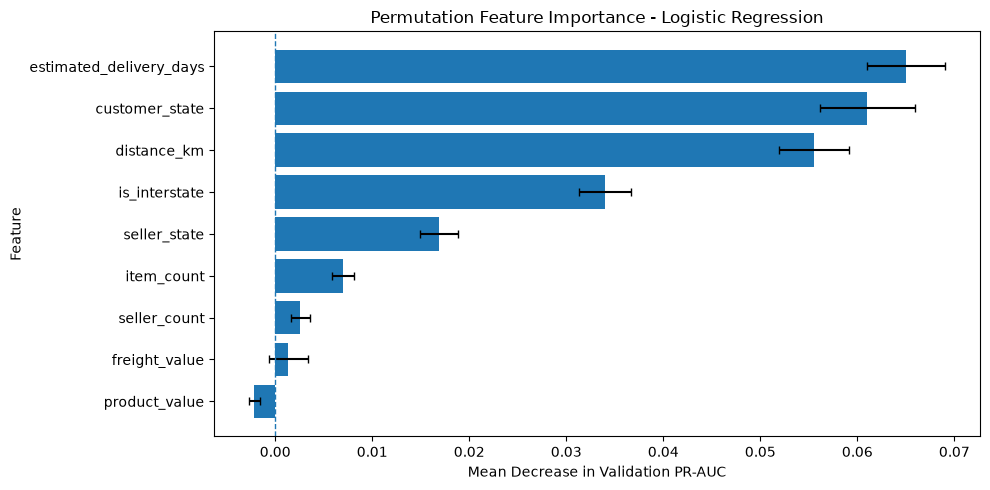

In [84]:
import matplotlib.pyplot as plt

# Sort features for a horizontal bar chart
plot_data = feature_importance.sort_values("Importance Mean")

plt.figure(figsize=(10, 5))

plt.barh(
    plot_data["Feature"],
    plot_data["Importance Mean"],
    xerr=plot_data["Importance Std"],
    capsize=3
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Permutation Feature Importance - Logistic Regression")
plt.xlabel("Mean Decrease in Validation PR-AUC")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## 8. Model Export

The selected Logistic Regression pipeline is saved for future use.

The exported artifact includes the fitted preprocessing pipeline and the list of required input features. This ensures that new orders can be processed using the same transformations applied during training.

The model is intended for exploratory risk ranking. Its predicted probabilities should be interpreted with caution due to the calibration and temporal stability limitations identified during evaluation.

In [85]:
import joblib
from pathlib import Path

# Identify the project directory
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Create a directory for exported models
models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)

# Store the fitted pipeline and required feature names
model_artifact = {
    "pipeline": best_logreg,
    "feature_names": list(best_features),
    "model_name": "Logistic Regression",
    "calibrated": False
}

# Save the model artifact
model_path = models_dir / "delivery_delay_logreg.joblib"

joblib.dump(model_artifact, model_path)

print(f"Model saved to: {model_path}")

Model saved to: C:\Users\marta\OneDrive\Desktop\DANE DO NOWEGO PROJEKTU\ecommerce-delivery-analytics\models\delivery_delay_logreg.joblib


In [86]:
import numpy as np

# Load the exported model
loaded_artifact = joblib.load(model_path)

loaded_model = loaded_artifact["pipeline"]
loaded_features = loaded_artifact["feature_names"]

# Select sample orders from validation data
sample_orders = X_val[loaded_features].head(5)

# Compare predictions before and after export
original_predictions = best_logreg.predict_proba(sample_orders)[:, 1]
loaded_predictions = loaded_model.predict_proba(sample_orders)[:, 1]

np.testing.assert_allclose(
    original_predictions,
    loaded_predictions
)

print("Model export verification successful.")
print("Required features:", loaded_features)

Model export verification successful.
Required features: ['estimated_delivery_days', 'distance_km', 'item_count', 'seller_count', 'product_value', 'freight_value', 'is_interstate', 'customer_state', 'seller_state']
